# Tutorial 2: Spatial Conditioning Features Extraction

Deriving topographic and hydrological indices (Slope, Aspect, Curvatures, TWI, and Stream Distance) from Digital Elevation Models using inundation_risk.spatial_features.

## 1. Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from inundation_risk.spatial_features import read_geotiff, compute_slope_aspect, compute_curvatures, compute_twi, extract_stream_network, compute_distance_to_stream

## 2. Read Benchmark DEM & Flow Accumulation

In [2]:
dem, meta = read_geotiff('../benchmarks/malang_raya/data/malang_dem_sample.tif')
accum, _ = read_geotiff('../benchmarks/malang_raya/data/malang_flow_accum_sample.tif')
print('DEM shape:', dem.shape, 'CRS:', meta['crs'])

DEM shape: (100, 100) CRS: EPSG:32749


## 3. Compute Topographic Morphometry

In [3]:
slope, aspect = compute_slope_aspect(dem, cell_size=30.0)
prof_c, plan_c = compute_curvatures(dem, cell_size=30.0)
twi = compute_twi(accum, slope, cell_size=30.0)
streams = extract_stream_network(accum, threshold_cells=500)
dist_stream = compute_distance_to_stream(streams, cell_size=30.0)

## 4. Visualize Spatial Conditioning Layers

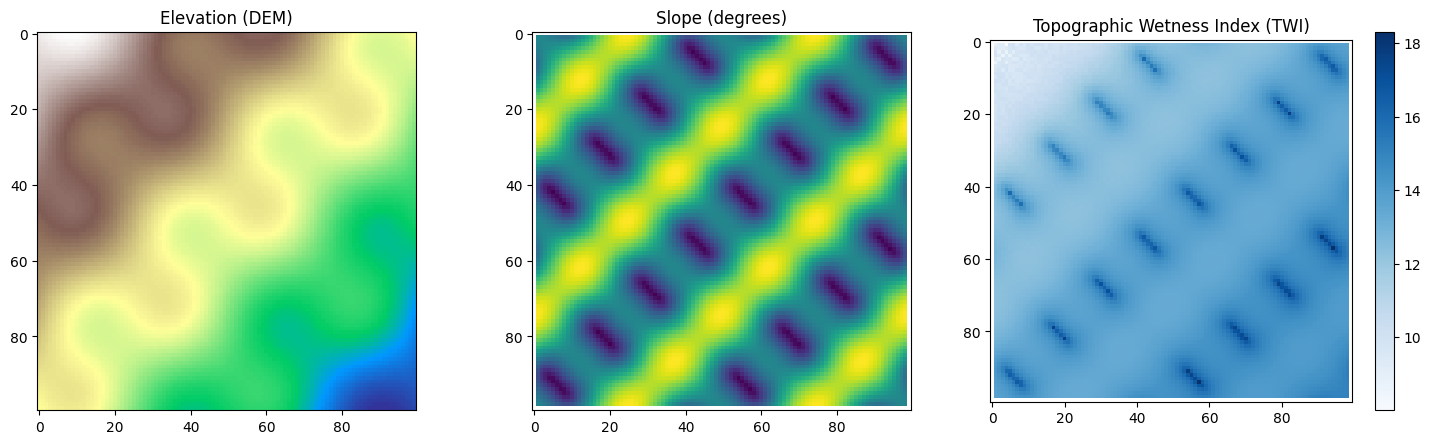

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].imshow(dem, cmap='terrain')
axes[0].set_title('Elevation (DEM)')
axes[1].imshow(slope, cmap='viridis')
axes[1].set_title('Slope (degrees)')
im = axes[2].imshow(twi, cmap='Blues')
axes[2].set_title('Topographic Wetness Index (TWI)')
plt.colorbar(im, ax=axes[2])
plt.tight_layout()
plt.show()